In [ ]:
# RNN(Recurrent Neural Network)
# 隠れ層に時刻情報（トレンド）を持たせて、再帰的（Recurrent）に更新する
# 勾配減衰という問題が発生するので、実際にはLSTMを使用する

# LSTM(Long Short Term Memory)
# 時系列データを取り扱う際に利用するモデル
# 長期的なトレンドと短期的なトレンドをそれぞれ計算し、未来の予測に使用する
# 忘却ゲート：長期的なトレンドをどれだけ覚えておくか
# 入力ゲート：長期的なトレンドに、どれだけ短期的なトレンドを反映するか
# 出力ゲート：長期的なトレンドから、短期的なトレンドを推定

# LSTMは線形層とセットで使用する

In [3]:
import torch
import torch.nn as  nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

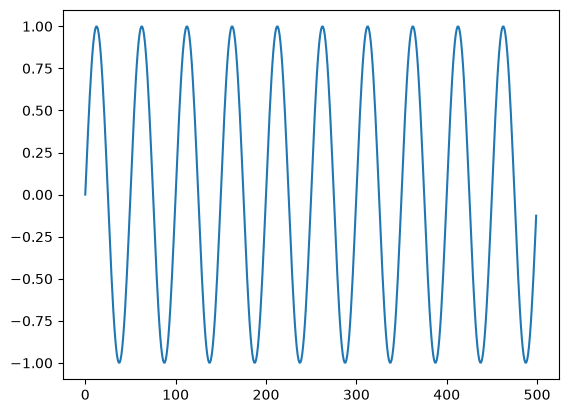

In [4]:
x = np.linspace(0, 499, 500)
y = np.sin(x * 2 * np.pi / 50)
plt.plot(x, y)

In [6]:
def make_sequence_data(y, num_sequence):
    num_data = len(y)
    seq_data = []
    target_data = []
    for i in range(num_data - num_sequence):
        seq_data.append(y[i:i+num_sequence]) # 入力の配列
        target_data.append(y[i+num_sequence:i+num_sequence+1]) # 正解の配列
    seq_arr = np.array(seq_data)
    target_arr = np.array(target_data)
    return seq_arr, target_arr

In [9]:
seq_length = 40
y_seq, y_target = make_sequence_data(y, seq_length)
y_seq.shape, y_target.shape

((460, 40), (460, 1))

In [10]:
num_test = 10 # 10個分だけテスト用として残しておく
y_seq_train = y_seq[:-num_test]
y_seq_test = y_seq[-num_test:]
y_target_train = y_target[:-num_test]
y_target_test = y_target[-num_test:]
y_seq_train.shape, y_seq_test.shape

((450, 40), (10, 40))

In [26]:
y_seq_t = torch.FloatTensor(y_seq_train)
y_target_t = torch.FloatTensor(y_target_train)

In [13]:
class LSTM(nn.Module):
    def __init__(self, hidden_size):
        super().__init__()
        self.hidden_size = hidden_size
        self.lstm = nn.LSTM(input_size=1, hidden_size=self.hidden_size)
        self.linear = nn.Linear(self.hidden_size, 1)

    def forward(self, x):
        x, _ = self.lstm(x) # 隠れ層やセルの状態がタプルに入ったものは使用しないので、変数への代入は行わない
        x_last = x[-1]
        x = self.linear(x_last)
        return x

In [14]:
model = LSTM(100)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [27]:
y_seq_t = y_seq_t.permute(1, 0)
y_target_t = y_target_t.permute(1, 0)
y_seq_t = y_seq_t.unsqueeze(dim=-1)
y_target_t = y_target_t.unsqueeze(dim=-1)
y_seq_t.size(), y_target_t.size(), 

(torch.Size([40, 450, 1]), torch.Size([1, 450, 1]))

In [28]:
num_epochs = 80
losses = []
for epoch in range(num_epochs):
    optimizer.zero_grad()
    output = model(y_seq_t)
    loss = criterion(output, y_target_t)
    loss.backward()
    losses.append(loss.item())
    optimizer.step()
    if epoch % 10 == 0:
        print("epoch: {}, loss: {}".format(epoch, loss.item()))

/Users/iwata-j/dev/ijproject/ai-learning/Pytorchによる深層学習入門/.venv/lib/python3.14/site-packages/torch/nn/modules/loss.py:630: UserWarning: Using a target size (torch.Size([1, 450, 1])) that is different to the input size (torch.Size([450, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


epoch: 0, loss: 0.5002824068069458
epoch: 10, loss: 0.339095801115036
epoch: 20, loss: 0.09859110414981842
epoch: 30, loss: 0.01684129238128662
epoch: 40, loss: 0.0019731938373297453
epoch: 50, loss: 0.0022243938874453306
epoch: 60, loss: 0.0010269788326695561
epoch: 70, loss: 0.00036871677730232477


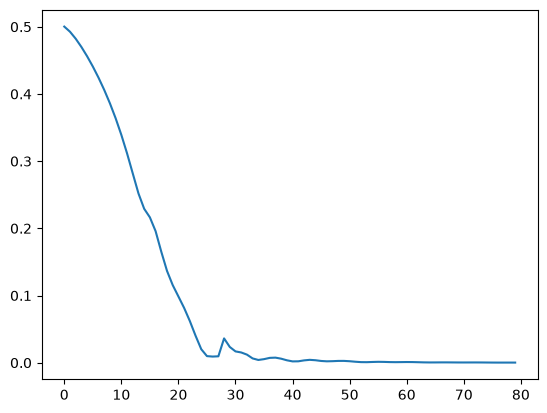

In [29]:
plt.plot(losses)

In [31]:
y_seq_test_t = torch.FloatTensor(y_seq_test)
y_seq_test_t = y_seq_test_t.permute(1, 0)
y_seq_test_t = y_seq_test_t.unsqueeze(dim=-1)
y_seq_test_t.size()

torch.Size([40, 10, 1])

In [32]:
y_pred = model(y_seq_test_t)
y_pred.size()

torch.Size([10, 1])

(450.0, 500.0)

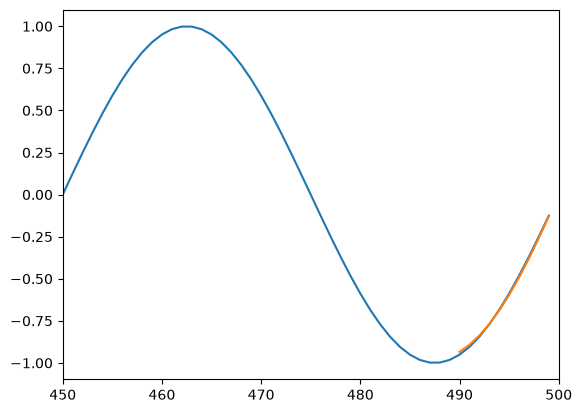

In [35]:
plt.plot(x, y)
plt.plot(np.arange(490, 500), y_pred.detach())
plt.xlim([450, 500])